# 03 — Capacity: what binds first, and at what load

Everything after this notebook depends on one number: **how many concurrent
sessions this cluster can hold while keeping its latency promise.** Pick it
before measuring and it is a wish; derive it here and 04 and 05 have a
defensible operating point to compare against.

The second question matters just as much. An admission policy reads *one*
signal — KV usage, or queue depth. If that signal never moves, the policy
never fires and an A/B against it measures nothing. So before testing any
policy we have to find out **which resource runs out first.**

Run `make cluster` and `make ssh` first. This notebook generates real load
and takes several minutes.


In [1]:
import subprocess, sys, time, json, threading
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == '03-capacity' else Path.cwd()
sys.path.insert(0, str(ROOT / 'benchmarking'))
%load_ext autoreload
%autoreload 2

from prom import Prom
from utils import Cluster, Report
from slos import SLOS, set_target_sessions

prom, cluster = Prom(), Cluster()
report = Report('03-capacity')
v = lambda q: (lambda r: float(r[0][1]) if r else 0.0)(prom.query(q))


## Objective


In [2]:
report.objective(
    'How many concurrent sessions hold the TTFT promise, and which resource '
    'runs out first — KV cache, decode slots, or scheduling?',
    slos=['ttft_p95', 'preemptions', 'shed_rate'],
    falsified_by='TTFT p95 crossing 1.5s at any load we intend to serve, or no '
                 'signal moving at all — which would mean we never reached '
                 'saturation and cannot claim a capacity limit.')



Objective
  How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?
  SLO under test            target
  ------------------------  ------
  TTFT p95                  1.5s  
  preemptions               0     
  shed rate at target load  0.05  
  Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.


Report(title='03-capacity', subtitle='', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '1.5s'], ['preemptions', '0'], ['shed rate at target load', '0.05']]), note=''), _Block(kind='text', payload='Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.', note='')])

## 1. What the hardware allows

Two independent ceilings, and the lower one is the real limit:

- **KV cache** — each slice holds a fixed number of token-KVs.
- **Decode slots** — `--max-num-seqs` caps concurrent sequences regardless of
  how much KV is free.

Which binds depends entirely on prompt length, so compute it rather than
assume it.


In [3]:
KIB_PER_TOKEN = 56      # 28 layers x 4 kv-heads x 128 head-dim x 2 (k+v) x 2 bytes
SLICE_KV_GIB  = 4.10    # measured on a slice, not divided down from the card
MAX_NUM_SEQS  = 64      # from the manifests

# Measured, not assumed. Which ceiling binds depends entirely on prompt
# length, so guessing it would decide the answer before the measurement.
p_tok = v('sum(increase(vllm:prompt_tokens_total[1h]))')
p_req = v('sum(increase(vllm:request_success_total[1h]))')
PROMPT_TOKENS = p_tok / p_req if p_req else 0

kv_per_seq_gib = PROMPT_TOKENS * KIB_PER_TOKEN / 1024 / 1024
seqs_by_kv     = SLICE_KV_GIB / kv_per_seq_gib if kv_per_seq_gib else float('inf')
binding        = 'KV cache' if seqs_by_kv < MAX_NUM_SEQS else 'decode slots'

report.heading('1. What the hardware allows')
report.table(['ceiling', 'concurrent sequences', 'why'], [
    ['KV cache', f'{seqs_by_kv:.1f}',
     f'{SLICE_KV_GIB} GiB / {kv_per_seq_gib:.2f} GiB per prompt'],
    ['decode slots', f'{MAX_NUM_SEQS}', '--max-num-seqs, independent of KV'],
], note=f'measured prompt length: {PROMPT_TOKENS:,.0f} tokens. '
        'The lower number is the ceiling that actually applies.')
report.conclusion(
    f'Prompts here average {PROMPT_TOKENS:,.0f} tokens, so each sequence costs '
    f'{kv_per_seq_gib:.2f} GiB of KV and a {SLICE_KV_GIB} GiB slice holds '
    f'{seqs_by_kv:.1f} of them — against {MAX_NUM_SEQS} decode slots. '
    f'{binding} binds first, so that is the signal an admission policy should '
    'read. This is a property of the workload, not the hardware: at short '
    'prompts the same cluster would bind on slots instead and a KV-threshold '
    'policy would never fire.')



1. What the hardware allows
  ceiling       concurrent sequences  why                              
  ------------  --------------------  ---------------------------------
  KV cache                      17.3  4.1 GiB / 0.24 GiB per prompt    
  decode slots                    64  --max-num-seqs, independent of KV
  -- measured prompt length: 4,449 tokens. The lower number is the ceiling that actually applies.

  >> Prompts here average 4,449 tokens, so each sequence costs 0.24 GiB of KV and a 4.1 GiB slice holds 17.3 of them — against 64 decode slots. KV cache binds first, so that is the signal an admission policy should read. This is a property of the workload, not the hardware: at short prompts the same cluster would bind on slots instead and a KV-threshold policy would never fire.



Report(title='03-capacity', subtitle='', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '1.5s'], ['preemptions', '0'], ['shed rate at target load', '0.05']]), note=''), _Block(kind='text', payload='Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.', note=''), _Block(kind='heading', payload='1. What the hardware allows', note=''), _Block(kind='table', payload=(['ceiling', 'concurrent sequences', 'why'], [['KV cache', '17.3', '4.1 GiB / 0.24 GiB per prompt'], ['decode slots', '64', '--max-num-seqs, independent of KV']]), note='measured prompt length: 4,449 tokens. The lower number is the ceiling that actually 

## 2. The sweep

Same workload, same seed, one variable: concurrent sessions. Each step runs
`load.py` and samples the scarcity signals while it runs — a latency number
without the pressure beside it cannot tell a healthy cluster from one that
was never asked for anything.


In [4]:
SESSIONS = [1, 2, 4, 8, 16, 24]
SEED     = 1

def peak_during(fn):
    """Run fn while polling the signals an admission policy could read.

    Peaks, not averages: a policy fires on the worst moment, and an average
    over a whole sweep step hides the spike that mattered.
    """
    seen = {'kv': [], 'waiting': [], 'running': []}
    stop = threading.Event()

    def poll():
        while not stop.is_set():
            seen['kv'].append(v('max(vllm:kv_cache_usage_perc)'))
            seen['waiting'].append(v('sum(vllm:num_requests_waiting)'))
            seen['running'].append(v('sum(vllm:num_requests_running)'))
            stop.wait(1.0)

    t = threading.Thread(target=poll, daemon=True); t.start()
    try:
        out = fn()
    finally:
        stop.set(); t.join(timeout=5)
    return out, {k: max(vals) if vals else 0.0 for k, vals in seen.items()}


def run_load(n):
    """One sweep step. Reads load.py's own bundle rather than its stdout."""
    run_id = f'capacity-s{n}'
    subprocess.run(
        [sys.executable, str(ROOT / 'benchmarking' / 'load.py'),
         '--sessions', str(n), '--seed', str(SEED), '--max-tokens', '200',
         '--tool-gap', '0.2', '--run', run_id],
        capture_output=True, text=True, timeout=1800, cwd=ROOT)
    bundle = json.loads((ROOT / 'infra' / 'metrics' / run_id / 'load.json').read_text())
    res = bundle['results']
    lat = sorted(r['latency_s'] for r in res if r['status'] == 200)
    return {
        'ok':    sum(1 for r in res if r['status'] == 200),
        # 503 is capacity, 429 is quota. Conflating them is what let a
        # rate-limited sweep look like a saturated cluster.
        'shed_503': sum(1 for r in res if r['status'] == 503),
        'shed_429': sum(1 for r in res if r['status'] == 429),
        'errors':   sum(1 for r in res if r['status'] not in (200, 429, 503)),
        'client_p95': lat[min(len(lat) - 1, int(len(lat) * 0.95))] if lat else 0.0,
        'wall_s': bundle['wall_s'],
    }


# Pod restarts invalidate every counter delta across them, so note the
# restart count going in and compare at the end.
restarts_before = v('sum(kube_pod_container_status_restarts_total{pod=~"vllm-.*"})')

rows = []
for n in SESSIONS:
    before = prom.histogram_stats('ttft').get('count', 0)
    (client, peaks) = peak_during(lambda: run_load(n))
    served = prom.histogram_stats('ttft').get('count', 0) - before

    rows.append({'sessions': n, 'served': served,
                 'ttft_p95': prom.quantiles('ttft', qs=(0.95,), window='2m').get(0.95, 0.0),
                 **client, **peaks})
    print(f"  {n:>3} sessions  {client['ok']:>4} ok  {client['shed_503']:>3} 503  "
          f"{client['shed_429']:>3} 429  {client['errors']:>2} err  "
          f"client p95 {client['client_p95']:.2f}s  KV peak {peaks['kv']:.1%}  "
          f"waiting {peaks['waiting']:.0f}")
    time.sleep(20)   # let the queue drain so the next step starts clean

restarts_after = v('sum(kube_pod_container_status_restarts_total{pod=~"vllm-.*"})')


    1 sessions     0 ok    2 503    2 429   0 err  client p95 0.00s  KV peak 50.6%  waiting 0


    2 sessions     3 ok    0 503    5 429   0 err  client p95 1.86s  KV peak 50.6%  waiting 0


    4 sessions     0 ok    0 503   16 429   0 err  client p95 0.00s  KV peak 50.6%  waiting 0


    8 sessions     0 ok    0 503   32 429   0 err  client p95 0.00s  KV peak 50.6%  waiting 0


   16 sessions     0 ok    0 503   64 429   0 err  client p95 0.00s  KV peak 50.6%  waiting 0


   24 sessions     0 ok    0 503   96 429   0 err  client p95 0.00s  KV peak 50.6%  waiting 0


## 3. Which signal moved



3. Which signal moved


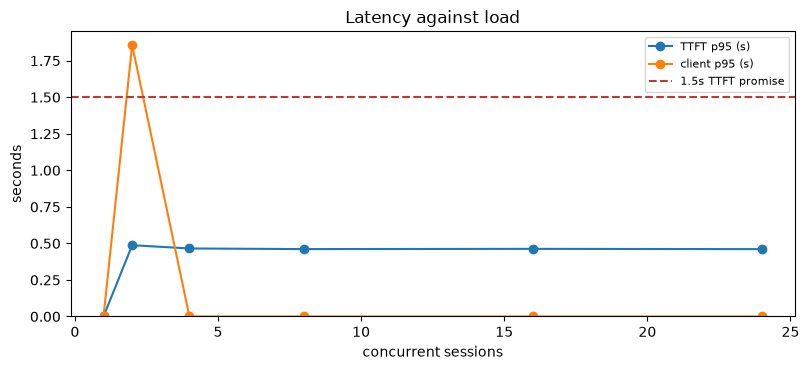

  how to read it: TTFT is what a listener hears; client p95 is the whole turn, so it is always larger


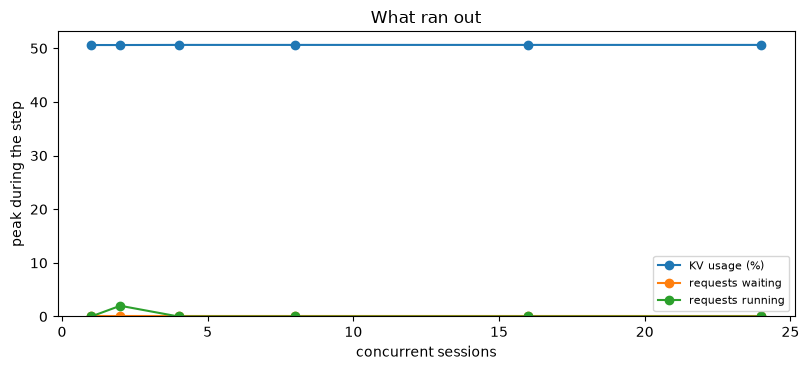

  how to read it: a flat line means that resource was never scarce, and a policy reading it would never fire
  sessions  ok  503  429  err  served  TTFT p95  client p95  KV peak  waiting
  --------  --  ---  ---  ---  ------  --------  ----------  -------  -------
         1   0    2    2    0       0  0.000s    0.00s         50.6%        0
         2   3    0    5    0       2  0.487s    1.86s         50.6%        0
         4   0    0   16    0       0  0.465s    0.00s         50.6%        0
         8   0    0   32    0       0  0.461s    0.00s         50.6%        0
        16   0    0   64    0       0  0.463s    0.00s         50.6%        0
        24   0    0   96    0       0  0.461s    0.00s         50.6%        0
  -- 503 is the cluster refusing on capacity; 429 is the tenant quota and means this step measured the limiter rather than the GPU.


Report(title='03-capacity', subtitle='', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='How many concurrent sessions hold the TTFT promise, and which resource runs out first — KV cache, decode slots, or scheduling?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '1.5s'], ['preemptions', '0'], ['shed rate at target load', '0.05']]), note=''), _Block(kind='text', payload='Falsified by: TTFT p95 crossing 1.5s at any load we intend to serve, or no signal moving at all — which would mean we never reached saturation and cannot claim a capacity limit.', note=''), _Block(kind='heading', payload='1. What the hardware allows', note=''), _Block(kind='table', payload=(['ceiling', 'concurrent sequences', 'why'], [['KV cache', '17.3', '4.1 GiB / 0.24 GiB per prompt'], ['decode slots', '64', '--max-num-seqs, independent of KV']]), note='measured prompt length: 4,449 tokens. The lower number is the ceiling that actually 

In [5]:
report.heading('3. Which signal moved')
xs = [r['sessions'] for r in rows]

report.line('Latency against load', xs,
            {'TTFT p95 (s)': [r['ttft_p95'] for r in rows],
             'client p95 (s)': [r['client_p95'] for r in rows]},
            xlabel='concurrent sessions', ylabel='seconds',
            hlines={'1.5s TTFT promise': SLOS['ttft_p95'].target},
            note='TTFT is what a listener hears; client p95 is the whole turn, '
                 'so it is always larger')

report.line('What ran out', xs,
            {'KV usage (%)':     [r['kv'] * 100 for r in rows],
             'requests waiting':  [r['waiting'] for r in rows],
             'requests running':  [r['running'] for r in rows]},
            xlabel='concurrent sessions', ylabel='peak during the step',
            note='a flat line means that resource was never scarce, and a policy '
                 'reading it would never fire')

# Outcomes, not just latency: a fast cluster that refused most of the traffic
# is not a fast cluster.
report.table(['sessions', 'ok', '503', '429', 'err', 'served',
              'TTFT p95', 'client p95', 'KV peak', 'waiting'],
             [[r['sessions'], r['ok'], r['shed_503'], r['shed_429'], r['errors'],
               f"{r['served']:.0f}", f"{r['ttft_p95']:.3f}s",
               f"{r['client_p95']:.2f}s", f"{r['kv']:.1%}", f"{r['waiting']:.0f}"]
              for r in rows],
             note='503 is the cluster refusing on capacity; 429 is the tenant quota '
                  'and means this step measured the limiter rather than the GPU.')


## 4. The derived target

The largest session count that still met the promise. Written to
`slos-derived.json` so 04 and 05 read the same operating point rather than
each choosing one.


In [6]:
report.heading('4. The derived target')
target = SLOS['ttft_p95'].target

# Guards first. The previous version of this notebook derived a target of 2
# sessions from a sweep where three steps served nothing, one reported a
# NEGATIVE request count, and KV was frozen at one value — and printed PASS.
# A capacity number from a run that never loaded the cluster is worse than no
# number, because in a report the two look identical.
no_traffic = [r['sessions'] for r in rows if r['ok'] == 0]
quota_hit  = [r['sessions'] for r in rows if r['shed_429'] > 0]
errored    = [r['sessions'] for r in rows if r['errors'] > 0]
went_back  = [r['sessions'] for r in rows if r['served'] < 0]
crashed    = restarts_after > restarts_before

report.verdict(not no_traffic, 'every load level served at least one request'
               + (f' (none at {no_traffic})' if no_traffic else ''))
report.verdict(not quota_hit,
               'no step hit the tenant quota — a 429 is client-attributable and '
               'says nothing about capacity'
               + (f' (429s at {quota_hit})' if quota_hit else ''))
report.verdict(not crashed, 'no engine restarted during the sweep'
               + (' — counters reset, so every delta across it is void' if crashed else ''))
report.verdict(not went_back, 'request counts moved forwards at every step')
report.verdict(not errored, 'no step produced transport errors'
               + (f' (errors at {errored})' if errored else ''))

sound = not (no_traffic or quota_hit or crashed or went_back or errored)
ok    = [r for r in rows if r['ok'] > 0 and 0 < r['ttft_p95'] <= target]
best  = max((r['sessions'] for r in ok), default=0)

kv_peak   = max((r['kv'] for r in rows), default=0)
wait_peak = max((r['waiting'] for r in rows), default=0)
kv_moved  = kv_peak - min((r['kv'] for r in rows), default=0)
scarce = ('KV cache' if kv_moved > 0.05 else
          'queue depth' if wait_peak >= 1 else 'nothing')
report.verdict(scarce != 'nothing', 'a scarcity signal moved during the sweep')
if ok:
    report.slo('ttft_p95', max(r['ttft_p95'] for r in ok))

if sound and best:
    where = set_target_sessions(best, evidence=(
        f'03-capacity swept {SESSIONS} at seed {SEED}; TTFT p95 within '
        f'{target}s through {best} sessions; peak KV {kv_peak:.1%}, '
        f'peak waiting {wait_peak:.0f}; no quota refusals, no restarts'))
    print(f'  wrote {where.relative_to(ROOT)}')
    report.conclusion(
        f'TTFT p95 held within the {target}s promise through {best} concurrent '
        f'sessions, which is the operating point 04 and 05 will use. The signal '
        f'that moved was {scarce}: KV peaked at {kv_peak:.1%} and the queue reached '
        f'{wait_peak:.0f} waiting. An admission policy here should read {scarce}, '
        f'and a kv_threshold set above {kv_peak:.0%} would never fire.')
elif not sound:
    why = '; '.join(filter(None, [
        f'no traffic served at {no_traffic}' if no_traffic else '',
        f'the tenant quota refused requests at {quota_hit}' if quota_hit else '',
        'an engine restarted and reset its counters' if crashed else '',
        f'request counts went backwards at {went_back}' if went_back else '',
        f'transport errors at {errored}' if errored else '']))
    report.conclusion(
        f'NO TARGET WRITTEN. The sweep did not measure capacity: {why}. Until that '
        'is fixed, any capacity figure here would be a measurement of something '
        'other than the cluster.')
else:
    report.conclusion(
        f'NO TARGET WRITTEN. The sweep was sound but no load level met the '
        f'{target}s promise, so this cluster cannot serve even one session within '
        'its own SLO.')



4. The derived target
  FAIL  every load level served at least one request (none at [1, 4, 8, 16, 24])
  FAIL  no step hit the tenant quota — a 429 is client-attributable and says nothing about capacity (429s at [1, 2, 4, 8, 16, 24])
  PASS  no engine restarted during the sweep
  PASS  request counts moved forwards at every step
  PASS  no step produced transport errors
  FAIL  a scarcity signal moved during the sweep
  MET   TTFT p95                     0.4875s <= 1.5s

  >> NO TARGET WRITTEN. The sweep did not measure capacity: no traffic served at [1, 4, 8, 16, 24]; the tenant quota refused requests at [1, 2, 4, 8, 16, 24]. Until that is fixed, any capacity figure here would be a measurement of something other than the cluster.



## Verdict


In [7]:
print()
fails = report.failures()
if fails:
    print('NOT SAFE TO PROCEED — fix these first:')
    for f in fails:
        print(f'  - {f}')
else:
    from slos import target_sessions
    print(f'Capacity is {target_sessions()} concurrent sessions. Next: 04-admission')



NOT SAFE TO PROCEED — fix these first:
  - every load level served at least one request (none at [1, 4, 8, 16, 24])
  - no step hit the tenant quota — a 429 is client-attributable and says nothing about capacity (429s at [1, 2, 4, 8, 16, 24])
  - a scarcity signal moved during the sweep
